In [31]:
from pathlib import Path
DATA_DIR = Path("../data")


In [32]:
import os

# Prepend TeX bin path to the PATH environment variable
os.environ['PATH'] = '/Library/TeX/texbin:' + os.environ['PATH']

In [33]:

import matplotlib
import matplotlib.pyplot as plt

matplotlib.use("pgf")
matplotlib.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'font.family': 'serif',
    'text.usetex': True,
    'pgf.rcfonts': False,
})

%matplotlib inline

In [1]:
data_path = '../data/baselines/PatchFinder'
top100_csv_filename = "predictions_top100_test.csv" # Name for the output CSV file
hybrid_csv_filename = "hybrid_similarity_test.csv"

In [2]:
import pandas as pd
import polars as pl
import os
top100_df = pl.read_csv(os.path.join(data_path, top100_csv_filename))
df = pd.read_csv(os.path.join(data_path, hybrid_csv_filename))
# drop Unnamed: 0 and ranked columns
df = df.drop(columns=['Unnamed: 0'])
df = df.drop_duplicates()


In [3]:
len(df["cve"].unique()), len(top100_df["cve"].unique())

(1252, 1252)

In [19]:
df

,cve,repo,commit_id,similarity,label,recall,precision,f1,fused_f1
0,CVE-2005-2351,muttmua/mutt,9123da3bfaef756b3c006d07db5ce57a517dda8d,0.000000,0,0.341001,0.122830,0.180605,0.180605
1,CVE-2005-2351,muttmua/mutt,ffe397957b52df598bfb68f95c58083023164c65,0.000000,0,0.175693,0.226958,0.198062,0.198062
2,CVE-2005-2351,muttmua/mutt,17b8d28760d839a497f1ecc0d51e57b916fb917d,0.000000,0,0.304260,0.151333,0.202130,0.202130
3,CVE-2005-2351,muttmua/mutt,9da28aea02dde0a7bc75fc71fa453be32a2dbf90,0.007443,0,0.174592,0.238606,0.201640,0.209084
4,CVE-2005-2351,muttmua/mutt,714e243e290cc047e9610fb84ee5dac76cfaeb84,0.002576,0,0.181056,0.244845,0.208173,0.210749
...,...,...,...,...,...,...,...,...,...
3901338,CVE-2022-35411,abersheeran/rpc.py,24a2781b73f8d500d8405682e458105d08391480,0.175148,0,0.426604,0.562400,0.485179,0.660327
3901339,CVE-2022-35411,abersheeran/rpc.py,a04fa00d8bcee13ec540b3e42758a6e6dfd1141f,0.222159,0,0.403545,0.508194,0.449864,0.672023
3901340,CVE-2022-35411,abersheeran/rpc.py,3859504738df9c9088ad4ba81fc5424c36f3bc19,0.217127,0,0.440322,0.548692,0.488570,0.705697
3901341,CVE-2022-35411,abersheeran/rpc.py,e60aba3d99297003a28069ce79650ada96d5711c,0.237770,0,0.461899,0.498091,0.479313,0.717083


In [6]:

top100_df_ranked = (
            top100_df
            .sort(["cve", "prediction"], descending=[False, True])
            .with_columns([
                (-pl.col("prediction")).rank("ordinal").over("cve").alias("rank")  # rank 1 = best
            ])
            #.filter(pl.col("rank") <= 10)  # Top 100 per CVE
        )
top100_df_ranked

cve,commit_id,label,prediction,rank
str,str,i64,f64,u32
"""CVE-2005-2351""","""3e88866dc60b5fa6aaba6fd7c1710c…",0,0.223517,1
"""CVE-2005-2351""","""c160ca1d74915f7b6a2fa18a5f4bdf…",0,0.006737,2
"""CVE-2005-2351""","""85a0ec8505d8cf9ab29765a07fc721…",0,0.004355,3
"""CVE-2005-2351""","""356ef5a5f9a508c8f935eb0839b1cc…",0,0.001546,4
"""CVE-2005-2351""","""781acdf0601fca98aadf1bbfdaae74…",0,0.001527,5
…,…,…,…,…
"""CVE-2022-35411""","""19135d734bba5fbd5d3121f4258918…",0,0.000009,96
"""CVE-2022-35411""","""d3a90ed8253cc04a84b2643f1a21e0…",0,0.000009,97
"""CVE-2022-35411""","""384e16e1b27ece70de449594205338…",0,0.000009,98


In [7]:
common_cols = df.columns.intersection(top100_df_ranked.columns).tolist()

merged_df = pd.merge(df, top100_df_ranked.to_pandas(), on=common_cols, how="left")
merged_df = pl.from_pandas(merged_df)

In [8]:
top100_df_ranked["cve"].unique().shape[0]

1252

In [9]:
top100_df_ranked

cve,commit_id,label,prediction,rank
str,str,i64,f64,u32
"""CVE-2005-2351""","""3e88866dc60b5fa6aaba6fd7c1710c…",0,0.223517,1
"""CVE-2005-2351""","""c160ca1d74915f7b6a2fa18a5f4bdf…",0,0.006737,2
"""CVE-2005-2351""","""85a0ec8505d8cf9ab29765a07fc721…",0,0.004355,3
"""CVE-2005-2351""","""356ef5a5f9a508c8f935eb0839b1cc…",0,0.001546,4
"""CVE-2005-2351""","""781acdf0601fca98aadf1bbfdaae74…",0,0.001527,5
…,…,…,…,…
"""CVE-2022-35411""","""19135d734bba5fbd5d3121f4258918…",0,0.000009,96
"""CVE-2022-35411""","""d3a90ed8253cc04a84b2643f1a21e0…",0,0.000009,97
"""CVE-2022-35411""","""384e16e1b27ece70de449594205338…",0,0.000009,98


In [9]:
top100_df_ranked.to_pandas().groupby('cve')["prediction"].value_counts()

cve             prediction
CVE-2005-2351   0.000007      2
                0.000004      1
                0.000004      1
                0.000004      1
                0.000004      1
                             ..
CVE-2022-35411  0.001446      1
                0.006278      1
                0.006478      1
                0.007891      1
                0.036002      1
Name: count, Length: 103456, dtype: int64

In [10]:
# Count how many CVEs still contain a label==1 in the top 10 ranked predictions
remaining_cves_with_label_1 = (
    top100_df_ranked
    .group_by("cve")
    .agg([
        (pl.col("label") == 1).any().alias("has_label_1")
    ])
    .filter(pl.col("has_label_1"))
    .height
)

total_cves = top100_df_ranked["cve"].unique().shape[0]
print(f"Number of CVEs with label 1 in top 10: {remaining_cves_with_label_1} of total {total_cves}")

Number of CVEs with label 1 in top 10: 762 of total 1252


In [11]:
# Get rank of the correct label (label == 1) per CVE
label_1_ranks = (
    merged_df
    .filter(pl.col("label") == 1)
    .select(["cve", "rank"])
)

# Mean Reciprocal Rank
mrr = (1 / label_1_ranks["rank"]).mean()
print(f"Mean Reciprocal Rank (MRR): {mrr:.4f}")

# Mean Rank
mean_rank = label_1_ranks["rank"].mean()
print(f"Mean Rank: {mean_rank:.2f}")

Mean Reciprocal Rank (MRR): 0.3740
Mean Rank: 10.67


In [12]:

cve_to_rank = dict(zip(label_1_ranks["cve"], label_1_ranks["rank"]))

# Step 2: All unique CVEs
all_cves = top100_df_ranked.select("cve").unique().to_series().to_list()


In [13]:
# Step 1: Calculate Reciprocal Rank (RR) for each CVE
def compute_rr(cve: str) -> float:
    rank = cve_to_rank.get(cve, None)
    if rank is None:
        return 0  # If no relevant result, reciprocal rank is 0
    return 1 / rank


# Step 2: Compute MMR
def compute_mmr() -> float:
    rr_values = [compute_rr(cve) for cve in all_cves]
    return sum(rr_values) / len(all_cves)

# Step 3: Print MMR value
mmr_value = compute_mmr()
print(f"Mean Reciprocal Rank (MMR): {mmr_value:.4f}")

Mean Reciprocal Rank (MMR): 0.2739


<function LinearScale.__init__ at 0x13355d8a0>
<function LogScale.__init__ at 0x13355e340>
<function SymmetricalLogScale.__init__ at 0x13355eca0>
<function AsinhScale.__init__ at 0x13355f420>
<function LogitScale.__init__ at 0x13355fba0>
<function FuncScale.__init__ at 0x13355dd00>
<function FuncScaleLog.__init__ at 0x13355e660>
<function Artist.get_agg_filter at 0x156229260>
<function Artist.get_alpha at 0x156228a40>
<function Artist.get_animated at 0x156228b80>
<function Artist.get_children at 0x1561cfce0>
<function Artist.get_clip_box at 0x156228e00>
<function Artist.get_clip_on at 0x156228d60>
<function Artist.get_clip_path at 0x156228ea0>
<function Artist.get_cursor_data at 0x15622a020>
<function Artist.get_figure at 0x1562287c0>
<function Artist.get_gid at 0x1562282c0>
<function Artist.get_in_layout at 0x156228c20>
<function Artist.get_label at 0x156229760>
<function Artist.get_mouseover at 0x15622a160>
<function Artist.get_path_effects at 0x156228720>
<function Artist.get_picker

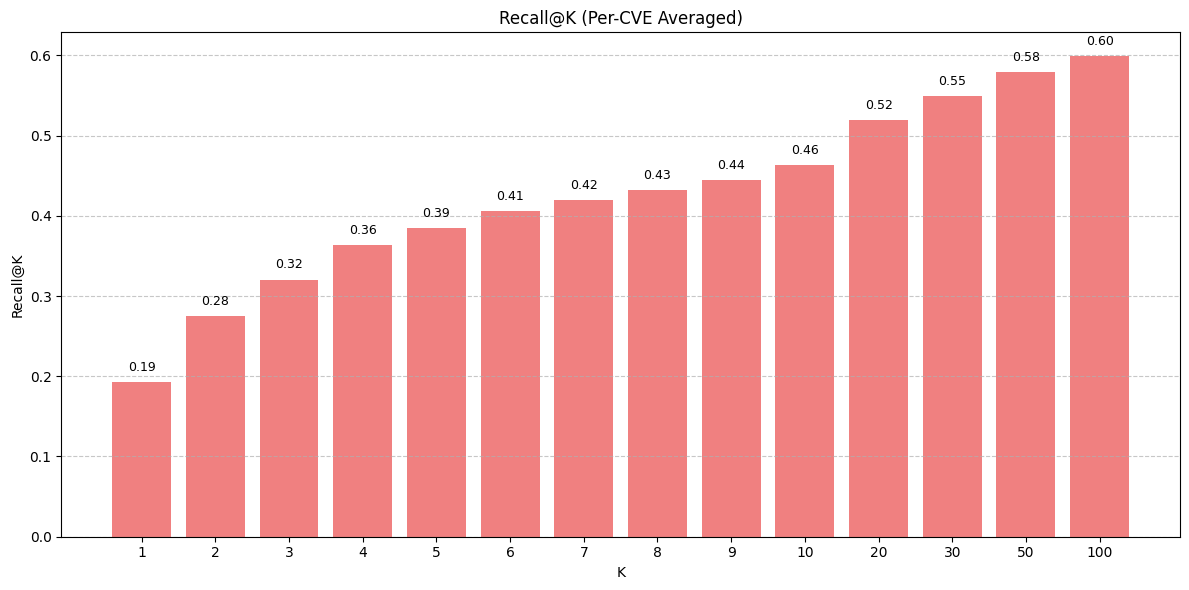

In [14]:
import polars as pl
import matplotlib.pyplot as plt

def compute_recall_at_k(df: pl.DataFrame, k: int) -> tuple[float, int]:
    grouped = {row[0]: row[1] for row in df.group_by("cve")}
    recall_per_cve = []

    for cve, subdf in grouped.items():
        total_relevant = subdf.filter(pl.col("label") == 1).height
        if total_relevant == 0:
            recall_per_cve.append(0.0)
        else:
            top_k = subdf.filter((pl.col("rank") <= k) & (pl.col("label") == 1)).height
            recall = top_k / total_relevant
            recall_per_cve.append(recall)

    avg_recall = sum(recall_per_cve) / len(recall_per_cve) if recall_per_cve else 0.0
    return avg_recall, len(recall_per_cve)


K_values = list(range(1, 11)) + [20, 30, 50, 100]
recall_values = [compute_recall_at_k(merged_df, k) for k in K_values]
recall_scores = [recall for recall, _ in recall_values]

plt.figure(figsize=(12, 6))
bars_recall = plt.bar([str(k) for k in K_values], recall_scores, color='lightcoral')
plt.title("Recall@K (Per-CVE Averaged)")
plt.xlabel("K")
plt.ylabel("Recall@K")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

for bar, recall in zip(bars_recall, recall_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{recall:.2f}", ha='center', va='bottom', fontsize=9)

plt.show()

In [23]:
total_relevant = merged_df.filter(pl.col("label") == 1).height
total_relevant

1940

In [29]:
retrieved_relevant = merged_df.filter(
        (pl.col("rank") <= 1000) & (pl.col("label") == 1)
    ).height
retrieved_relevant

1290

In [26]:
merged_df["cve"].unique().shape[0]

1252

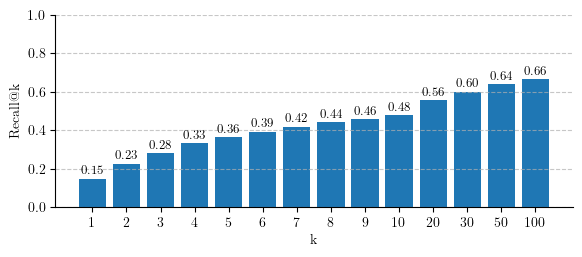

In [42]:
import polars as pl

def compute_overall_recall_at_k(df: pl.DataFrame, k: int) -> float:
    total_relevant = df.filter(pl.col("label") == 1).height
    retrieved_relevant = df.filter(
        (pl.col("rank") <= k) & (pl.col("label") == 1)
    ).height
    return retrieved_relevant / total_relevant if total_relevant > 0 else 0.0

recall_overall_scores = [compute_overall_recall_at_k(merged_df, k) for k in K_values]

fig = plt.figure(figsize=(12, 6))
ax = fig.gca()
bars_recall = ax.bar([str(k) for k in K_values], recall_overall_scores)
#ax.set_title("Overall Recall@k")
ax.set_xlabel("k")
ax.set_ylabel("Recall@k")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 1)
for bar, recall in zip(bars_recall, recall_overall_scores):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{recall:.2f}", ha='center', va='bottom', fontsize=9)

for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.set_size_inches(w=3.3374*2, h=(2.5))
#fig.tight_layout()

fig.savefig(f'../figures/PatchFinder_recall.pdf', bbox_inches='tight')
fig.savefig(f'../figures/PatchFinder_recall.pgf', bbox_inches='tight')
plt.show()

Manual Efforts@K values:
ME@1: 1.0000
ME@2: 1.8147
ME@3: 2.5543
ME@4: 3.2556
ME@5: 3.8858
ME@6: 4.4984
ME@7: 5.0927
ME@8: 5.6773
ME@9: 6.2388
ME@10: 6.7907
ME@20: 11.7907
ME@30: 16.3522
ME@50: 24.8538
ME@100: 44.7508


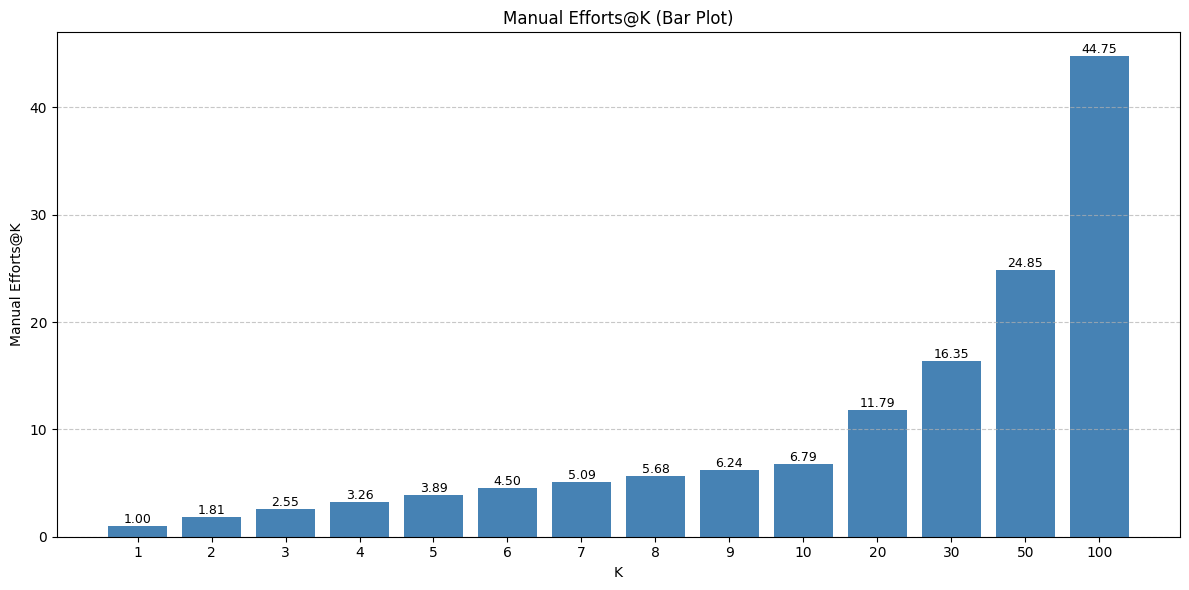

In [16]:
import polars as pl
import matplotlib.pyplot as plt

# Load your ranked DataFrame
# df_ranked = pl.read_csv("your_file.csv")

# Step 3: Compute ME@K
def compute_me_at_k(k: int) -> float:
    total_effort = 0
    for cve in all_cves:
        rank = cve_to_rank.get(cve, None)
        if rank is None:
            total_effort += k
        else:
            total_effort += min(rank, k)
    return total_effort / len(all_cves)

# Step 4: K values and compute
K_values = list(range(1, 11)) + [20, 30, 50, 100]
me_values = [compute_me_at_k(k) for k in K_values]

# Step 5: Print
print("Manual Efforts@K values:")
for k, me in zip(K_values, me_values):
    print(f"ME@{k}: {me:.4f}")

# Step 6: Bar plot
plt.figure(figsize=(12, 6))
bars = plt.bar([str(k) for k in K_values], me_values, color='steelblue')
plt.title("Manual Efforts@K (Bar Plot)")
plt.xlabel("K")
plt.ylabel("Manual Efforts@K")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Annotate bars with values
for bar, value in zip(bars, me_values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{value:.2f}", ha='center', va='bottom', fontsize=9)

plt.show()

In [17]:
k_values = list(range(1, 11)) + [20, 30, 50, 100]
df_ranked

NameError: name 'df_ranked' is not defined

In [ ]:
def compute_metrics(cve_data, k_values):
    """Compute metrics (recall@k, MRR, Manual Efforts) for the model outputs."""
    recalls = {k: [] for k in k_values}
    mrrs = []
    manual_efforts = {k: [] for k in k_values}
    manual_efforts_sum = {k: 0 for k in k_values}
    manual_efforts_count = {k: 0 for k in k_values}
    rank_data = []
    
    for cve, data in cve_data.items():
        data.sort(key=lambda x: x[0], reverse=True)
        ranks = [(i + 1, label) for i, (_, label) in enumerate(data)]

        for rank, label in ranks:
            rank_data.append({'cve': cve, 'rank': rank, 'label': label})
        
        # Compute metrics using the ranks
        positive_ranks = [rank for rank, label in ranks if label == 1]
        
        for k in k_values:
            top_k_counts = sum(1 for rank in positive_ranks if rank <= k)
            recalls[k].append(top_k_counts / len(positive_ranks) if positive_ranks else 0)

            if positive_ranks:
                min_rank_within_k = min([rank for rank in positive_ranks if rank < k], default=k)
            else:
                min_rank_within_k = k
            
            manual_efforts[k].append(min_rank_within_k)
            
            manual_efforts_sum[k] += min_rank_within_k
            manual_efforts_count[k] += 1
            
            # effort_k = sum(min(rank, k) for rank in ranks) / len(ranks) if ranks else 0
            # manual_efforts[k].append(effort_k)


        reciprocal_ranks = [1 / (rank) for rank in positive_ranks]
        mrrs.append(sum(reciprocal_ranks) / len(reciprocal_ranks) if reciprocal_ranks else 0)

    avg_recalls = {k: sum(recalls[k]) / len(recalls[k]) if recalls[k] else 0 for k in k_values}
    avg_mrr = sum(mrrs) / len(mrrs) if mrrs else 0
    avg_manual_efforts = {k: sum(manual_efforts[k]) / len(manual_efforts[k]) if manual_efforts[k] else 0 for k in k_values}
    avg_manual_efforts[1] = 1.0
    
    return avg_recalls, avg_mrr, avg_manual_efforts


compute_metrics(df_ranked.to_pandas().to_dict(), [1])

AttributeError: 'dict' object has no attribute 'sort'

In [ ]:
df_ranked.to_pandas()

,cve,commit_id,label,label_pred,rank
0,CVE-2000-0948,1ac2cd144ee56227590933f885c39b595f47cf35,0,0.002979,1
1,CVE-2000-0948,a9deb66c1b567f37a01275bd15b6e0a060eb75ef,0,0.002371,2
2,CVE-2000-0948,bba4cd2cf0269ec933cb2ccf92743bbcebf3c2da,0,0.002371,3
3,CVE-2000-0948,0bc9d7632c00b0323fd53972817513dd302990be,0,0.002371,4
4,CVE-2000-0948,8346fea6cc42e405aaad94d22c305949c201a288,0,0.002371,5
...,...,...,...,...,...
128260,CVE-2022-35411,24a2781b73f8d500d8405682e458105d08391480,0,0.000037,96
128261,CVE-2022-35411,97ac15f7c8ef84fc28cfef3df79e5d599736e186,0,0.000037,97
128262,CVE-2022-35411,a04fa00d8bcee13ec540b3e42758a6e6dfd1141f,0,0.000037,98
128263,CVE-2022-35411,3859504738df9c9088ad4ba81fc5424c36f3bc19,0,0.000035,99


In [ ]:
df_ranked.to_pandas()[["cve", "" "label"]]

,cve,commit_id,label,label_pred,rank
0,CVE-2000-0948,1ac2cd144ee56227590933f885c39b595f47cf35,0,0.002979,1
1,CVE-2000-0948,a9deb66c1b567f37a01275bd15b6e0a060eb75ef,0,0.002371,2
2,CVE-2000-0948,bba4cd2cf0269ec933cb2ccf92743bbcebf3c2da,0,0.002371,3
3,CVE-2000-0948,0bc9d7632c00b0323fd53972817513dd302990be,0,0.002371,4
4,CVE-2000-0948,8346fea6cc42e405aaad94d22c305949c201a288,0,0.002371,5
...,...,...,...,...,...
128260,CVE-2022-35411,24a2781b73f8d500d8405682e458105d08391480,0,0.000037,96
128261,CVE-2022-35411,97ac15f7c8ef84fc28cfef3df79e5d599736e186,0,0.000037,97
128262,CVE-2022-35411,a04fa00d8bcee13ec540b3e42758a6e6dfd1141f,0,0.000037,98
128263,CVE-2022-35411,3859504738df9c9088ad4ba81fc5424c36f3bc19,0,0.000035,99
